# Análisis de resultados desde MLflow

Recupera del servidor de MLflow las corridas de `src/modeling` (LoRA, SciBERT y TF-IDF) y muestra, por corrida:

1. Un resumen de la corrida y las curvas de pérdida de entrenamiento y de validación (dev), con el punto que eligió el early stopping, para ver desde cuándo hay sobreajuste.
2. Las métricas de dev y test (A6), en global y por clase, con el intervalo de confianza del 95 % del F1-macro-9.
3. Las matrices de confusión de dev y test.

Al final, una tabla con todas las corridas, los rankings por F1-macro-9 y cómo bajar el mejor modelo de una corrida.

**Todo sale de MLflow:** parámetros, curvas, métricas finales, `metrics_summary.json` y `config.json` de cada corrida. No lee archivos locales: las corridas que se registraron completas en MLflow no dejan nada en la máquina donde corrieron.

**Entrada:** el servidor en `MLFLOW_IP` (o `MLFLOW_TRACKING_URI`, o la IP escrita en `mlflow_ip.txt`), los experimentos en `EXPERIMENTOS` (separados por comas; por defecto `EvidenCite-A4-A7`, el de `configs/base.yaml`) y, si se quiere, un filtro de MLflow en `FILTRO` (por ejemplo `params.model_family = 'llm_lora'`). Las tres son variables de entorno o se cambian en la celda 1.

**Requisitos:** `pip install mlflow-skinny pandas matplotlib jinja2` (jinja2 es lo que usa pandas para mostrar las tablas con título). No necesita el repo ni torch.

In [1]:
# @title 1 · Librerías y parámetros
import json
import os
import tempfile
import warnings
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_DISABLE_TELEMETRY", "true")
os.environ.setdefault("MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR", "false")   # una barra por cada JSON leído ensucia la salida
warnings.filterwarnings("ignore", message="IProgress not found")        # Jupyter sin ipywidgets

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from mlflow import MlflowClient
from mlflow.artifacts import download_artifacts, list_artifacts


def servidor_mlflow() -> str:
    """Dirección del servidor: MLFLOW_TRACKING_URI, MLFLOW_IP o la IP escrita en mlflow_ip.txt (aquí o en el repo)."""
    candidatas = [os.environ.get("MLFLOW_TRACKING_URI", ""), os.environ.get("MLFLOW_IP", "")]
    for archivo in (Path("mlflow_ip.txt"), Path("..") / "mlflow_ip.txt"):
        if archivo.is_file():
            candidatas.append(archivo.read_text(encoding="utf-8").strip())
    for c in candidatas:
        if c.strip():
            return c.strip().rstrip("/") if "://" in c else f"http://{c.strip()}"
    raise ValueError("Define MLFLOW_IP (ip:puerto del servidor de MLflow) o escríbela en mlflow_ip.txt")


MLFLOW_URI = servidor_mlflow()
EXPERIMENTOS = [e.strip() for e in os.environ.get("EXPERIMENTOS", "pipeline_nuevo").split(",") if e.strip()]
FILTRO = os.environ.get("FILTRO", "")   # filtro de MLflow; vacío: todas las corridas FINISHED de los experimentos
VENTANA_SUAVIZADO = 5      # puntos del registro de entrenamiento (uno cada logging_steps pasos) para la media móvil
N_BOOTSTRAP = 2000         # réplicas para el intervalo de confianza del 95 % del F1-macro-9
GUARDAR = os.environ.get("GUARDAR", "0") == "1"   # 1: guarda figuras (PNG) y tablas (CSV) en analisis/
cliente = MlflowClient(tracking_uri=MLFLOW_URI)

# Colores: cada conjunto tiene siempre el mismo color en todas las figuras (paleta validada para daltonismo).
SUPERFICIE, TINTA, TINTA_2, TENUE, REJILLA, EJE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COLOR = {"train": "#2a78d6", "dev": "#eb6834", "test": "#1baf7a"}
SECUENCIAL = LinearSegmentedColormap.from_list(
    "azul", ["#fcfcfb", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": EJE, "axes.linewidth": 1, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": EJE, "ytick.color": EJE, "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2,
    "axes.axisbelow": True, "legend.frameon": False, "legend.labelcolor": TINTA_2, "lines.linewidth": 2,
    "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round", "figure.dpi": 110,
})
print(f"MLflow: {MLFLOW_URI} · experimentos: {', '.join(EXPERIMENTOS)}" + (f" · filtro: {FILTRO}" if FILTRO else ""))

MLflow: http://100.58.138.131:8080 · experimentos: pipeline_nuevo


In [2]:
# @title 2 · Lectura de las corridas desde MLflow
CURVAS = ("loss", "eval_loss", "eval_f1_macro", "learning_rate", "epoch")


def leer_json(run_id: str, ruta: str) -> dict | None:
    """Un JSON de los artefactos de la corrida, bajado a una carpeta temporal que se borra enseguida."""
    with tempfile.TemporaryDirectory() as tmp:
        try:
            archivo = cliente.download_artifacts(run_id, ruta, tmp)
        except Exception:   # la corrida no tiene ese artefacto
            return None
        return json.loads(Path(archivo).read_text(encoding="utf-8"))


def curva(run_id: str, clave: str) -> pd.DataFrame:
    """Historia de una métrica: una fila por paso, con su valor."""
    puntos = cliente.get_metric_history(run_id, clave)
    return pd.DataFrame({"paso": [p.step for p in puntos], "valor": [p.value for p in puntos]}).sort_values("paso")


def cargar_corridas(experimentos: list[str], filtro: str = "") -> list[dict]:
    """Las corridas FINISHED de los experimentos, con sus parámetros, métricas, curvas y artefactos.

    Salta las que no tienen metrics_summary.json (no son de src/modeling o no terminaron de subir). Si dos corridas
    se llaman igual, se queda con la más reciente.
    """
    ids = {}
    for nombre in experimentos:
        exp = cliente.get_experiment_by_name(nombre)
        if exp is None:
            print(f"No existe el experimento «{nombre}» en {MLFLOW_URI}")
        else:
            ids[exp.experiment_id] = nombre
    if not ids:
        raise ValueError("Ningún experimento encontrado: revisa EXPERIMENTOS")
    filtros = ["attributes.status = 'FINISHED'"] + ([filtro] if filtro else [])
    encontradas = cliente.search_runs(list(ids), " and ".join(filtros), order_by=["attributes.start_time DESC"])
    por_nombre = {}
    for r in encontradas:
        nombre = r.info.run_name
        if nombre in por_nombre:
            print(f"Salto una corrida anterior con el mismo nombre: {nombre} ({r.info.run_id})")
            continue
        resumen = leer_json(r.info.run_id, "metrics_summary.json")
        if resumen is None:
            print(f"Salto {nombre}: no tiene metrics_summary.json")
            continue
        corrida = cliente.get_run(r.info.run_id)
        salidas = corrida.outputs.model_outputs if corrida.outputs else []
        por_nombre[nombre] = {
            "nombre": nombre, "titulo": nombre, "run_id": r.info.run_id, "experimento": ids[r.info.experiment_id],
            "params": r.data.params, "metricas": r.data.metrics, "tags": r.data.tags,
            "resumen": resumen, "config": leer_json(r.info.run_id, "config.json") or {},
            "curvas": {k: curva(r.info.run_id, k) for k in CURVAS if k in r.data.metrics},
            "modelo": salidas[-1].model_id if salidas else None,
            "minutos": (r.info.end_time - r.info.start_time) / 60000 if r.info.end_time else None,
        }
    return [por_nombre[n] for n in sorted(por_nombre)]


def etiquetas(c: dict) -> list[str]:
    """Las 9 clases en el orden de la matriz de confusión (el de CANONICAL_9_CLASSES)."""
    return list(c["resumen"]["dev_metrics_a6"]["per_class_f1"])


def a_epoca(c: dict):
    """Función paso → época, con la curva «epoch» que registra el Trainer. None si la corrida no la tiene."""
    epocas = c["curvas"].get("epoch")
    if epocas is None or epocas.empty:
        return None
    return lambda pasos: np.interp(pasos, epocas["paso"], epocas["valor"])


def mejor_paso(c: dict) -> int | None:
    """El paso que eligió el early stopping (best_step) o, si no está, el del máximo eval_f1_macro."""
    if "best_step" in c["metricas"]:
        return int(c["metricas"]["best_step"])
    f1 = c["curvas"].get("eval_f1_macro")
    return int(f1.loc[f1["valor"].idxmax(), "paso"]) if f1 is not None and not f1.empty else None

In [3]:
# @title 3 · Tablas
def mostrar(df: pd.DataFrame, titulo: str, decimales: int = 3, formatos: dict | None = None) -> None:
    """Muestra una tabla con su título. Sin jinja2, imprime el título y la tabla simple.

    `formatos` fija el formato de columnas concretas, por ejemplo {"lr": "{:.0e}"} para que 1e-4 no se vea como 0.000.
    """
    formatos = formatos or {}
    try:
        estilo = df.style.set_caption(titulo).format(precision=decimales, na_rep="—")
        if formatos:
            estilo = estilo.format(formatos, precision=decimales, na_rep="—")
        estilo = estilo.set_table_styles([{"selector": "caption", "props": "caption-side: top; text-align: left; "
                                           "font-weight: bold; font-size: 1.05em; color: #0b0b0b; padding: 6px 0;"}])
        display(estilo)
    except ImportError:
        print(f"\n{titulo}")
        simple = df.round(decimales)
        for columna, formato in formatos.items():
            simple[columna] = df[columna].map(lambda v: formato.format(v) if pd.notna(v) else "—")
        display(simple)


def ic95_f1_macro(confusion) -> tuple[float, float]:
    """Intervalo de confianza del 95 % del F1-macro-9 por bootstrap. Remuestrear instancias equivale a remuestrear
    las celdas (clase real, predicción) de la matriz de confusión con sus frecuencias."""
    cm = np.asarray(confusion, dtype=float)
    n, k = int(cm.sum()), len(cm)
    if n == 0:
        return (np.nan, np.nan)
    muestras = np.random.default_rng(0).multinomial(n, (cm / n).ravel(), size=N_BOOTSTRAP).reshape(-1, k, k)
    tp = np.diagonal(muestras, axis1=1, axis2=2)
    denominador = 2 * tp + (muestras.sum(1) - tp) + (muestras.sum(2) - tp)
    f1 = np.where(denominador > 0, 2 * tp / np.maximum(denominador, 1), 0.0)
    return tuple(np.percentile(f1.mean(1), [2.5, 97.5]))


def tabla_resumen(c: dict) -> pd.DataFrame:
    """Datos clave de la corrida, de su entrenamiento y de su curva de pérdida en dev, como tabla campo → valor."""
    p, m, op = c["params"], c["metricas"], c["resumen"]["operational_metrics_a7"]
    convertir = a_epoca(c)
    epoca = (lambda paso: f"{float(convertir(paso)):.2f}") if convertir else (lambda paso: f"paso {paso}")
    mejor = mejor_paso(c)
    filas = {
        "experimento": c["experimento"], "familia": p.get("model_family"),
        "modelo": p.get("pretrained_model_name_or_path", "TF-IDF + regresión logística"),
        "variante LoRA": p.get("lora_variant"), "configuración": p.get("configuration"),
        "lr": p.get("learning_rate"), "scheduler": p.get("lr_scheduler"), "épocas planeadas": p.get("num_train_epochs"),
        "lote efectivo": (int(p["per_device_train_batch_size"]) * int(p.get("gradient_accumulation_steps", 1))
                          if "per_device_train_batch_size" in p else None),
        "evaluaciones de dev por época": p.get("evals_per_epoch"),
        "época del mejor punto de dev": epoca(mejor) if mejor else None,
        "pasos entrenados / planeados": (f"{int(m['trained_steps'])} / {int(m['planned_steps'])}"
                                         if "trained_steps" in m else None),
        "parada temprana": ({True: "sí", False: "no"}[m["trained_steps"] < m["planned_steps"]]
                            if "trained_steps" in m else None),
    }
    evals = c["curvas"].get("eval_loss")
    if evals is not None and len(evals) > 0:
        i_min = evals["valor"].idxmin()
        minima, final = evals.loc[i_min, "valor"], evals["valor"].iloc[-1]
        filas |= {"época de la pérdida dev mínima": epoca(evals.loc[i_min, "paso"]),
                  "pérdida dev mínima": f"{minima:.3f}", "pérdida dev al final": f"{final:.3f}",
                  "subida de la pérdida dev desde el mínimo": f"{final / minima - 1:+.0%}"}
    filas |= {"minutos de entrenamiento": f"{op['train_wall_time_sec'] / 60:.1f}",
              "minutos de la corrida": f"{c['minutos']:.1f}" if c["minutos"] else None,
              "memoria pico (MB)": f"{op['peak_memory_mb']:.0f}" if op["peak_memory_mb"] else None,
              "GPU": c["tags"].get("gpu"), "parámetros entrenables": f"{op['trainable_ratio_pct']:.2f} %",
              "latencia (ms por instancia)": f"{op['inference_latency_ms_per_instance']:.2f}",
              "modelo registrado": c["modelo"]}
    return pd.DataFrame({"valor": {k: ("—" if v is None else str(v)) for k, v in filas.items()}})


def tabla_dev_test(c: dict) -> pd.DataFrame:
    """Métricas A6 de dev y test lado a lado, con el intervalo de confianza del F1-macro-9."""
    columnas = {}
    for split in ("dev", "test"):
        m = c["resumen"].get(f"{split}_metrics_a6")
        if not m:
            continue
        inferior, superior = ic95_f1_macro(m["confusion_matrix"])
        columnas[split] = {
            "F1-macro-9": m["macro_f1_all_9"],
            "IC95 inferior": inferior, "IC95 superior": superior,
            "macro-F1 de las clases presentes": m["macro_f1_present"], "micro-F1 (accuracy)": m["micro_f1"],
            "F1 ponderado": m["weighted_f1"], "precisión macro": m["macro_precision"], "recall macro": m["macro_recall"],
            "n": sum(m["per_class_support"].values()),
        }
    tabla = pd.DataFrame(columnas).astype(object)
    tabla.loc["n"] = tabla.loc["n"].map(lambda v: int(v) if pd.notna(v) else v)
    return tabla


def tabla_por_clase(c: dict) -> pd.DataFrame:
    """Precisión, recall, F1 y soporte por clase en dev y test (columnas agrupadas por split)."""
    partes = {}
    for split in ("dev", "test"):
        m = c["resumen"].get(f"{split}_metrics_a6")
        if m:
            df = pd.DataFrame({"P": m["per_class_precision"], "R": m["per_class_recall"], "F1": m["per_class_f1"],
                               "n": m["per_class_support"]})
            df["n"] = df["n"].astype("Int64")
            partes[split] = df
    return pd.concat(partes, axis=1).reindex(etiquetas(c))

In [4]:
# @title 4 · Gráficas
def guardar_figura(fig, nombre: str) -> None:
    """Si GUARDAR=1, guarda la figura como PNG en analisis/<nombre>.png."""
    if GUARDAR:
        Path("analisis").mkdir(exist_ok=True)
        fig.savefig(Path("analisis") / f"{nombre}.png", dpi=160, bbox_inches="tight")


def graficar_perdidas(c: dict) -> None:
    """Pérdida de entrenamiento y de dev en el mismo eje, y debajo el F1-macro-9 de dev, con el mejor punto marcado.

    Si la pérdida de dev sube mientras la de entrenamiento sigue bajando, el modelo está sobreajustando; el early
    stopping se queda con el punto de mejor F1-macro-9 de dev (línea vertical).
    """
    registro, evals, f1 = (c["curvas"].get(k) for k in ("loss", "eval_loss", "eval_f1_macro"))
    if all(x is None or x.empty for x in (registro, evals)):
        print("Sin curvas de entrenamiento (TF-IDF no entrena por pasos).")
        return
    convertir = a_epoca(c)
    eje = convertir or (lambda pasos: pasos)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]},
                                   constrained_layout=True)
    fig.suptitle(c["titulo"], x=0.01, ha="left", fontsize=12, color=TINTA)
    finales = {}
    if registro is not None and not registro.empty:
        x = eje(registro["paso"])
        ax1.plot(x, registro["valor"], color=COLOR["train"], lw=1, alpha=0.3)
        suave = registro["valor"].rolling(VENTANA_SUAVIZADO, min_periods=1).mean()
        ax1.plot(x, suave, color=COLOR["train"], label=f"entrenamiento (media móvil de {VENTANA_SUAVIZADO} registros)")
        finales["entrenamiento"] = (x.iloc[-1] if hasattr(x, "iloc") else x[-1], suave.iloc[-1])
    if evals is not None and not evals.empty:
        x = eje(evals["paso"])
        ax1.plot(x, evals["valor"], color=COLOR["dev"], marker="o", markersize=8, markeredgecolor=SUPERFICIE,
                 markeredgewidth=2, label="validación (dev)")
        finales["dev"] = (x.iloc[-1] if hasattr(x, "iloc") else x[-1], evals["valor"].iloc[-1])
    ax1.set_ylabel(f"pérdida ({c['params'].get('loss_type', 'entropía cruzada')})")
    ax1.set_ylim(bottom=0)
    ax1.legend(loc="upper right")
    if len(finales) == 2:   # etiquetas directas al final de cada curva, solo si no se pisan
        (_, y1), (_, y2) = finales.values()
        if abs(y1 - y2) > 0.06 * ax1.get_ylim()[1]:
            for texto, (xf, yf) in finales.items():
                ax1.annotate(f"{texto} {yf:.2f}", (xf, yf), xytext=(6, 0), textcoords="offset points",
                             va="center", fontsize=9, color=TINTA_2)

    titulo_f1 = "F1-macro-9 de dev (el criterio del early stopping)"
    if f1 is not None and not f1.empty:
        ax2.plot(eje(f1["paso"]), f1["valor"], color=COLOR["dev"], marker="o", markersize=8,
                 markeredgecolor=SUPERFICIE, markeredgewidth=2)
        ax2.set_ylabel("F1-macro-9")
    mejor, f1_test = mejor_paso(c), c["metricas"].get("test_macro_f1_all_9")
    f1_mejor = c["metricas"].get("best_eval_f1_macro")
    if mejor:
        for ax in (ax1, ax2):
            ax.axvline(eje(mejor), color=TENUE, lw=1)
        mejor_arriba = f1_test is None or f1_mejor is None or f1_mejor >= f1_test
        if f1_mejor is not None:
            ax2.annotate(f"mejor: {f1_mejor:.3f}", (eje(mejor), f1_mejor),
                         xytext=(8, -14) if f1_test is None else (8, 3 if mejor_arriba else -3),
                         textcoords="offset points", va="baseline" if f1_test is None else
                         ("bottom" if mejor_arriba else "top"), fontsize=9, color=TINTA_2)
        if f1_test is not None:
            ax2.plot([eje(mejor)], [f1_test], marker="D", markersize=8, color=COLOR["test"],
                     markeredgecolor=SUPERFICIE, markeredgewidth=2, linestyle="none")
            ax2.annotate(f"test: {f1_test:.3f}", (eje(mejor), f1_test), xytext=(8, -3 if mejor_arriba else 3),
                         textcoords="offset points", va="top" if mejor_arriba else "bottom", fontsize=9,
                         color=TINTA_2)
            abajo, arriba = ax2.get_ylim()
            ax2.set_ylim(abajo, arriba + 0.1 * (arriba - abajo))
            titulo_f1 += " · rombo: test en el mejor punto"
    ax2.set_title(titulo_f1, fontsize=10, color=TINTA_2)
    ax1.set_title("pérdida de entrenamiento y de validación · línea vertical: punto elegido por el early stopping",
                  fontsize=10, color=TINTA_2)
    ax2.set_xlabel("época" if convertir else "paso de optimizador")
    guardar_figura(fig, f"{c['nombre']}_perdidas")
    plt.show()


def graficar_f1_por_clase(c: dict, tabla: pd.DataFrame) -> None:
    """Barras horizontales con el F1 de cada clase en dev y en test."""
    splits = [s for s in ("dev", "test") if s in tabla.columns.get_level_values(0)]
    clases = list(tabla.index)
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(clases) + 1.2), constrained_layout=True)
    alto = 0.8 / len(splits)
    for k, split in enumerate(splits):
        f1 = tabla[(split, "F1")]
        y = np.arange(len(clases)) + (k - (len(splits) - 1) / 2) * alto
        ax.barh(y, f1.fillna(0), height=alto, color=COLOR[split], edgecolor=SUPERFICIE, linewidth=2, label=split)
        for yi, valor in zip(y, f1):
            if valor == 0:   # una barra de largo 0 no se ve: se marca con su valor
                ax.annotate("0", (0, yi), xytext=(4, 0), textcoords="offset points", va="center",
                            fontsize=8.5, color=TINTA_2)
    ax.set_yticks(np.arange(len(clases)), clases)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("F1")
    ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=len(splits))
    ax.set_title(f"{c['titulo']} · F1 por clase", fontsize=11)
    guardar_figura(fig, f"{c['nombre']}_f1_por_clase")
    plt.show()


def graficar_confusiones(c: dict) -> None:
    """Matrices de confusión de dev y test, solo con las clases que aparecen (en el gold o en las predicciones).

    El color es el porcentaje de cada fila (el recall de esa clase real); cada celda muestra el conteo y ese %.
    """
    splits = [s for s in ("dev", "test") if c["resumen"].get(f"{s}_metrics_a6")]
    nombres_clases = etiquetas(c)
    fig, axes = plt.subplots(1, len(splits), figsize=(6.4 * len(splits), 5.6), constrained_layout=True, squeeze=False)
    fig.suptitle(f"{c['titulo']} · matrices de confusión", x=0.01, ha="left", fontsize=12, color=TINTA)
    for ax, split in zip(axes[0], splits):
        m = np.array(c["resumen"][f"{split}_metrics_a6"]["confusion_matrix"])
        presentes = [i for i in range(len(m)) if m[i].sum() > 0 or m[:, i].sum() > 0]
        sub = m[np.ix_(presentes, presentes)]
        totales = sub.sum(axis=1, keepdims=True)
        pct = np.divide(sub, totales, out=np.zeros(sub.shape), where=totales > 0)
        imagen = ax.imshow(pct, cmap=SECUENCIAL, vmin=0, vmax=1)
        for i in range(len(presentes)):
            for j in range(len(presentes)):
                if sub[i, j]:
                    ax.text(j, i, f"{sub[i, j]}\n{pct[i, j]:.0%}", ha="center", va="center", fontsize=8.5,
                            color="#ffffff" if pct[i, j] > 0.55 else TINTA)
        nombres = [nombres_clases[i] for i in presentes]
        ax.set_xticks(range(len(presentes)), nombres, rotation=35, ha="right")
        ax.set_yticks(range(len(presentes)), [f"{n} ({t})" for n, t in zip(nombres, totales[:, 0])])
        ax.set_xticks(np.arange(-0.5, len(presentes)), minor=True)   # 2 px del fondo entre celdas, sin bordes
        ax.set_yticks(np.arange(-0.5, len(presentes)), minor=True)
        ax.grid(which="minor", color=SUPERFICIE, linewidth=2)
        ax.grid(which="major", visible=False)
        ax.tick_params(which="both", length=0)
        for lado in ax.spines.values():
            lado.set_visible(False)
        ax.set_xlabel("predicción")
        ax.set_ylabel("clase real (soporte)")
        ax.set_title(f"{split} · n = {int(m.sum())}", fontsize=10, color=TINTA_2)
    barra = fig.colorbar(imagen, ax=axes[0].tolist(), shrink=0.75, format=PercentFormatter(xmax=1, decimals=0))
    barra.set_label("% de la fila (recall de la clase real)", color=TINTA_2)
    barra.outline.set_visible(False)
    guardar_figura(fig, f"{c['nombre']}_confusion")
    plt.show()


def graficar_test_con_ic(tabla: pd.DataFrame) -> None:
    """F1-macro-9 de test de cada corrida con su intervalo de confianza del 95 %, ordenado de mayor a menor."""
    datos = tabla.dropna(subset=["F1-macro-9 test"]).sort_values("F1-macro-9 test")
    if datos.empty:
        return
    fig, ax = plt.subplots(figsize=(8.5, 0.42 * len(datos) + 1.4), constrained_layout=True)
    y = np.arange(len(datos))
    ax.hlines(y, datos["IC95 test inf."], datos["IC95 test sup."], color=COLOR["test"], lw=2)
    ax.plot(datos["F1-macro-9 test"], y, "o", markersize=9, color=COLOR["test"], markeredgecolor=SUPERFICIE,
            markeredgewidth=2)
    ax.set_yticks(y, datos.index)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("F1-macro-9 de test (punto) e intervalo de confianza del 95 % (línea)")
    ax.set_title("F1-macro-9 de test por corrida · si los intervalos se solapan, la diferencia puede ser ruido",
                 fontsize=11)
    guardar_figura(fig, "test_con_ic95")
    plt.show()

In [5]:
# @title 5 · Cargar las corridas
corridas = cargar_corridas(EXPERIMENTOS, FILTRO)
print(f"{len(corridas)} corridas desde {MLFLOW_URI}")

2026/11/04 14:47:20 WARNING mlflow.store.artifact.http_artifact_repo: Presigned download is unavailable (HTTP 404). Falling back to proxied download.


Salto Qwen3-8B-Base_lora_B_lr1e-4_e4_main: no tiene metrics_summary.json
4 corridas desde http://100.58.138.131:8080


## Por corrida

Para cada corrida: resumen, curvas de pérdida, métricas de dev frente a test, métricas por clase y matrices de confusión.

- **Cómo leer las curvas:** si la pérdida de dev sube mientras la de entrenamiento sigue bajando, hay sobreajuste desde ese punto. El early stopping se queda con los pesos del mejor punto de dev según el F1-macro-9 (`eval_f1_macro`, línea vertical), así que la evaluación final no usa los pesos sobreajustados.
- **F1-macro-9:** promedia las 9 clases de Lyu; con dataset_2 las 9 tienen ejemplos en dev y en test. El intervalo del 95 % se calcula por bootstrap sobre la matriz de confusión: si los intervalos de dos corridas se solapan, la diferencia puede ser ruido.
- **TF-IDF** no entrena por pasos: no tiene curvas ni mejor punto.

### Qwen3-8B-Base_lora_B_lr1e-4_e4

,valor
experimento,pipeline_nuevo
familia,llm_lora
modelo,Qwen/Qwen3-8B-Base
variante LoRA,lora
configuración,B
lr,0.0001
scheduler,wsd
épocas planeadas,4
lote efectivo,16
evaluaciones de dev por época,2


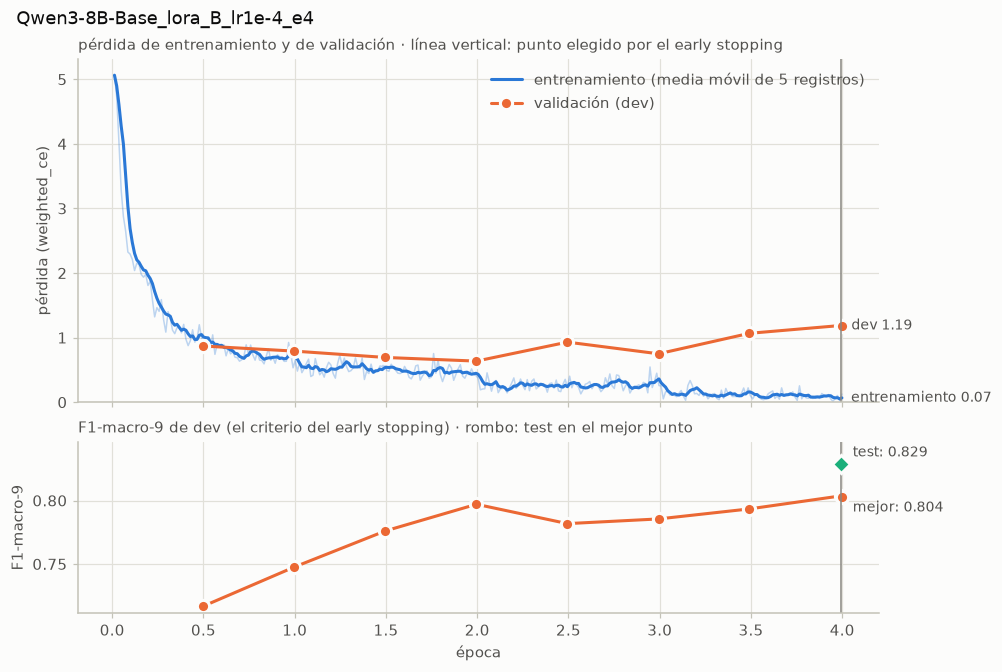

,dev,test
F1-macro-9,0.804,0.829
IC95 inferior,0.788,0.815
IC95 superior,0.818,0.843
macro-F1 de las clases presentes,0.804,0.829
micro-F1 (accuracy),0.805,0.827
F1 ponderado,0.805,0.827
precisión macro,0.802,0.828
recall macro,0.806,0.830
n,2783,2798


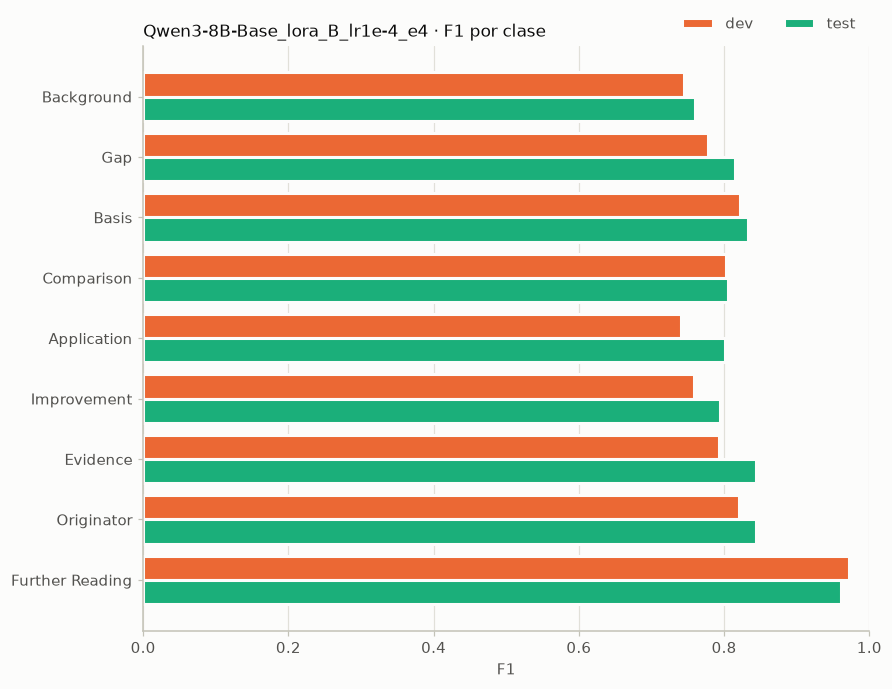

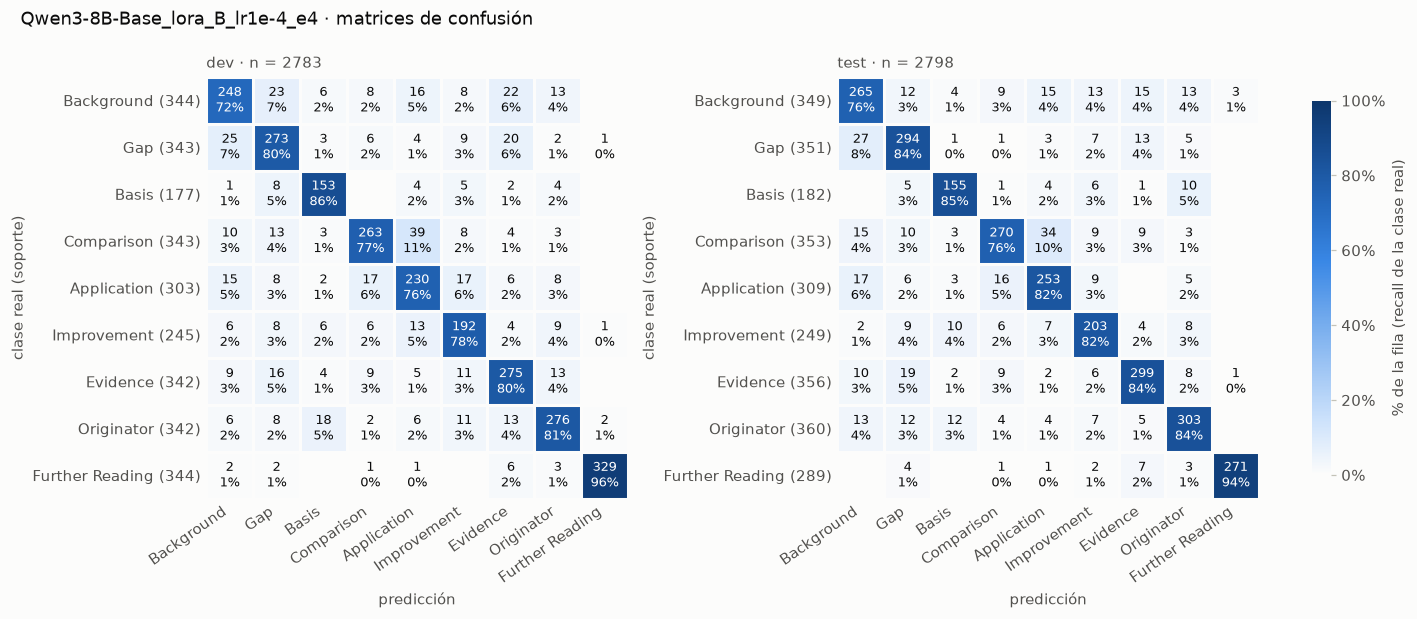

### Qwen3-8B-Base_lora_B_lr1e-4_e4_512

,valor
experimento,pipeline_nuevo
familia,llm_lora
modelo,Qwen/Qwen3-8B-Base
variante LoRA,lora
configuración,B
lr,0.0001
scheduler,wsd
épocas planeadas,4
lote efectivo,16
evaluaciones de dev por época,2


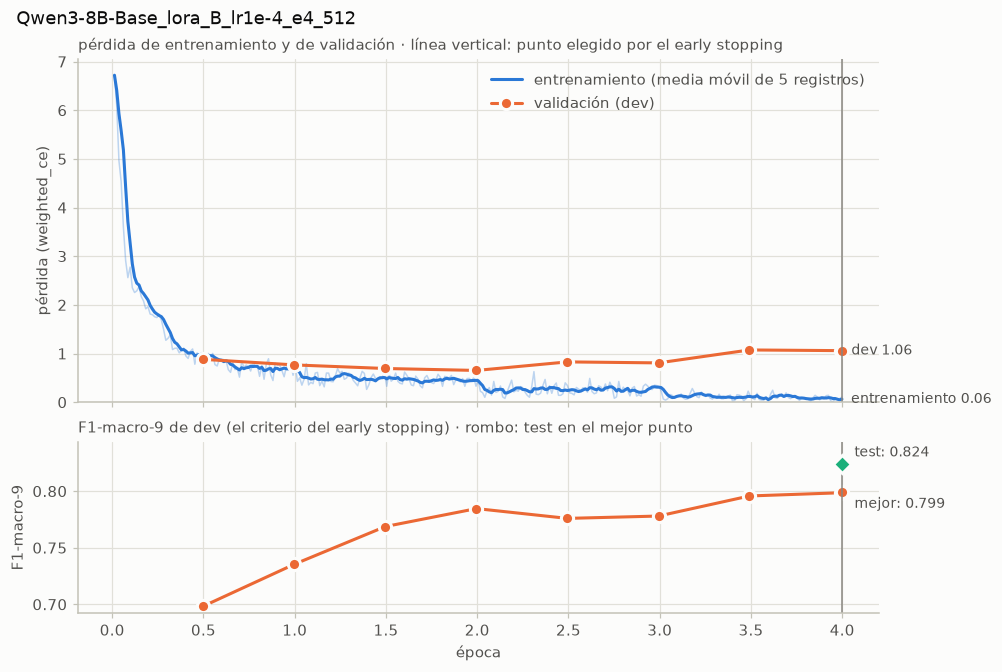

,dev,test
F1-macro-9,0.799,0.824
IC95 inferior,0.783,0.809
IC95 superior,0.814,0.837
macro-F1 de las clases presentes,0.799,0.824
micro-F1 (accuracy),0.801,0.820
F1 ponderado,0.801,0.820
precisión macro,0.798,0.824
recall macro,0.800,0.824
n,2783,2798


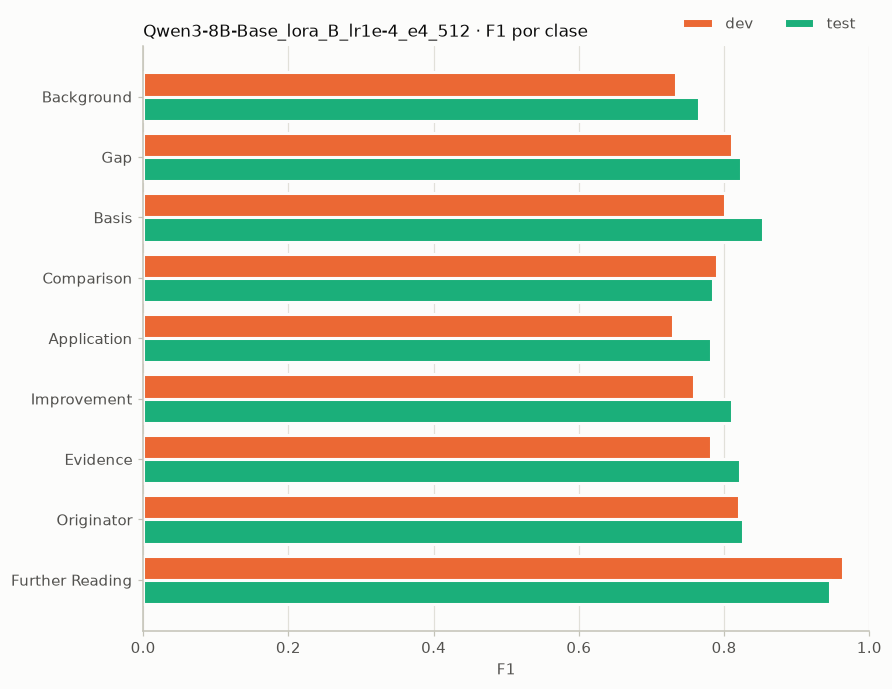

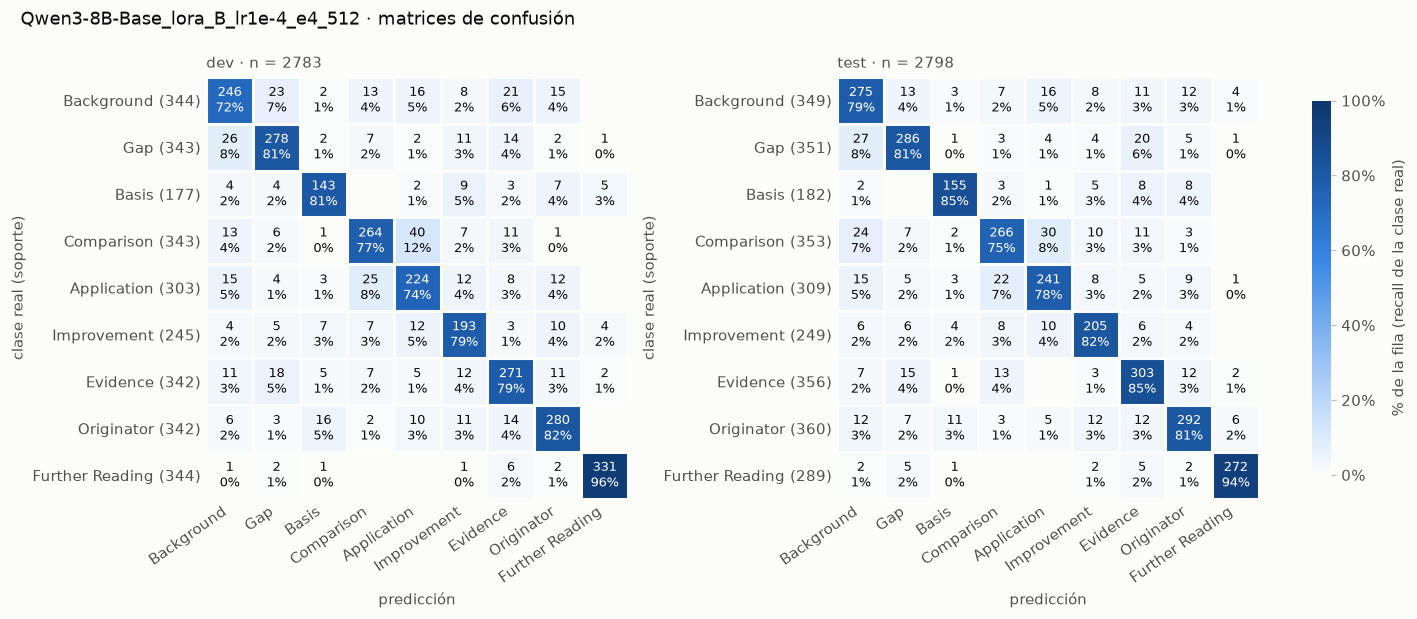

### qwen8b_compilado_1024

,valor
experimento,pipeline_nuevo
familia,llm_lora
modelo,Qwen/Qwen3-8B-Base
variante LoRA,lora
configuración,B
lr,0.0001
scheduler,wsd
épocas planeadas,4
lote efectivo,16
evaluaciones de dev por época,1


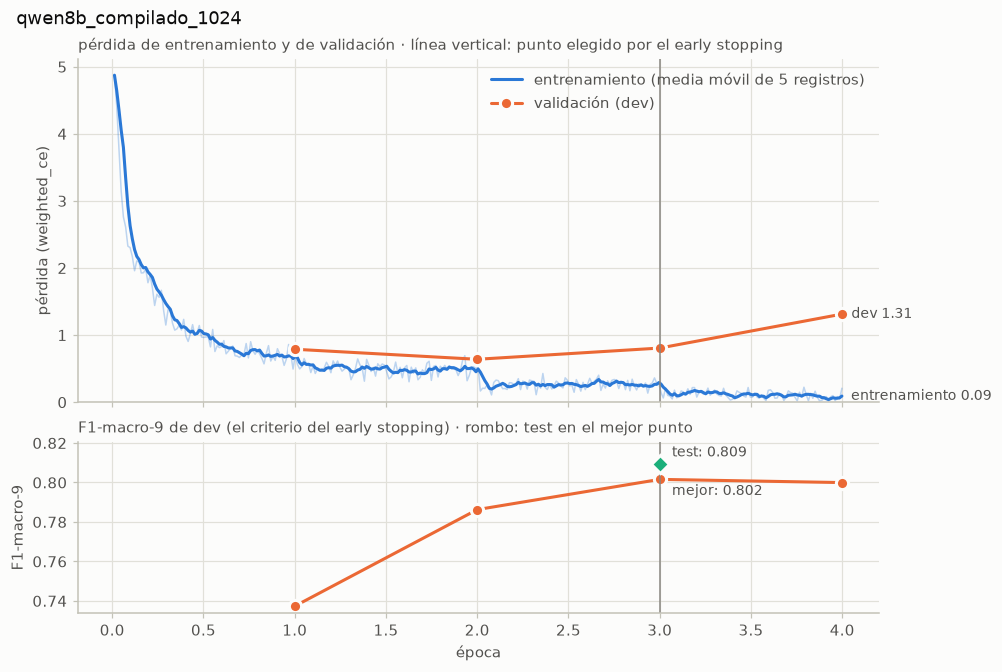

,dev,test
F1-macro-9,0.802,0.809
IC95 inferior,0.787,0.794
IC95 superior,0.815,0.823
macro-F1 de las clases presentes,0.802,0.809
micro-F1 (accuracy),0.805,0.808
F1 ponderado,0.805,0.808
precisión macro,0.802,0.811
recall macro,0.805,0.810
n,2783,2798


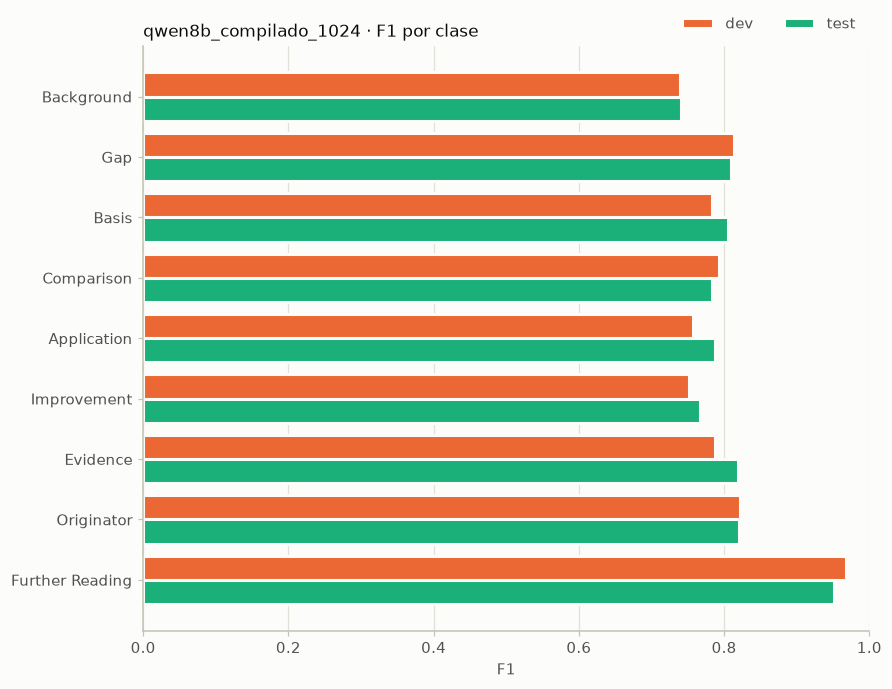

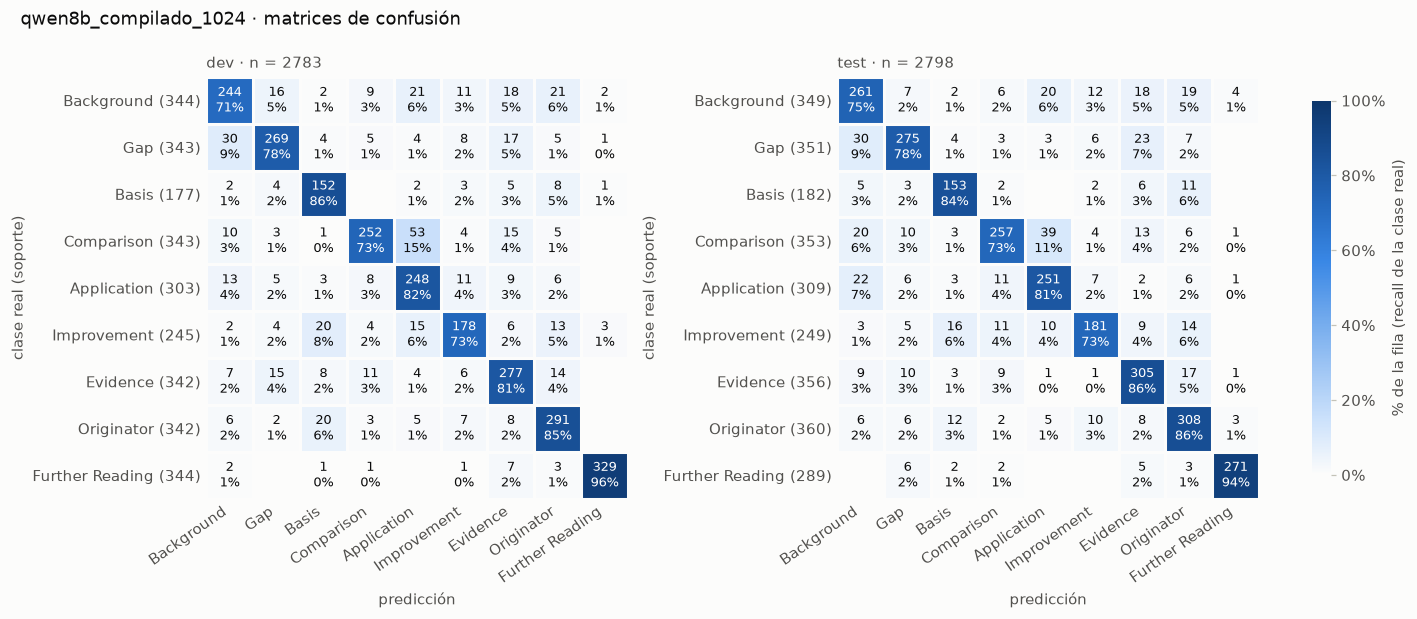

### qwen8b_compilado_512

,valor
experimento,pipeline_nuevo
familia,llm_lora
modelo,Qwen/Qwen3-8B-Base
variante LoRA,lora
configuración,B
lr,0.0001
scheduler,wsd
épocas planeadas,4
lote efectivo,16
evaluaciones de dev por época,1


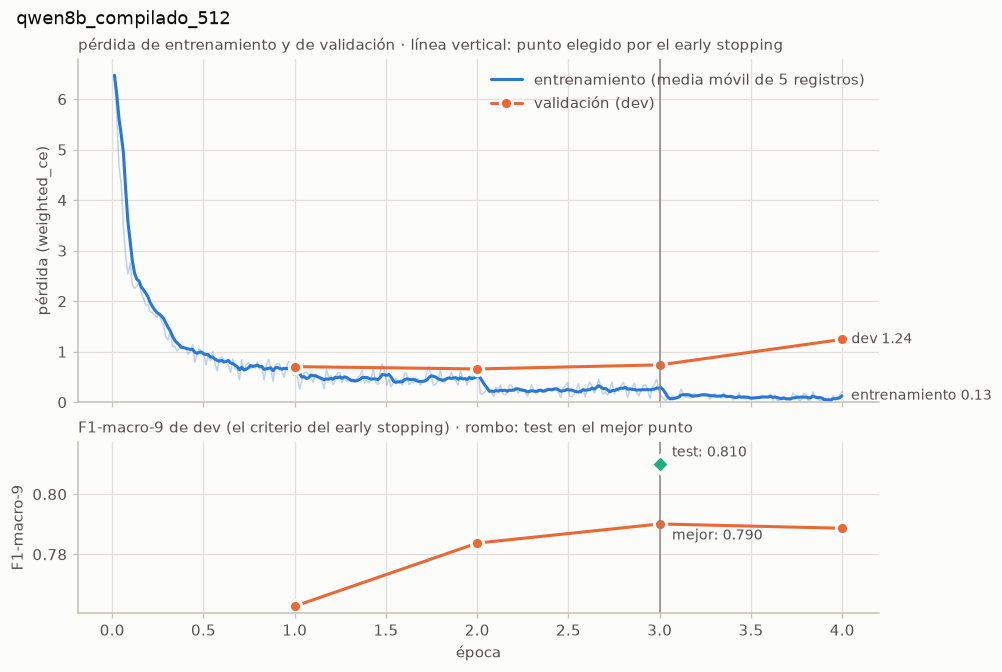

,dev,test
F1-macro-9,0.790,0.810
IC95 inferior,0.774,0.796
IC95 superior,0.806,0.824
macro-F1 de las clases presentes,0.790,0.810
micro-F1 (accuracy),0.793,0.807
F1 ponderado,0.793,0.808
precisión macro,0.791,0.814
recall macro,0.789,0.807
n,2783,2798


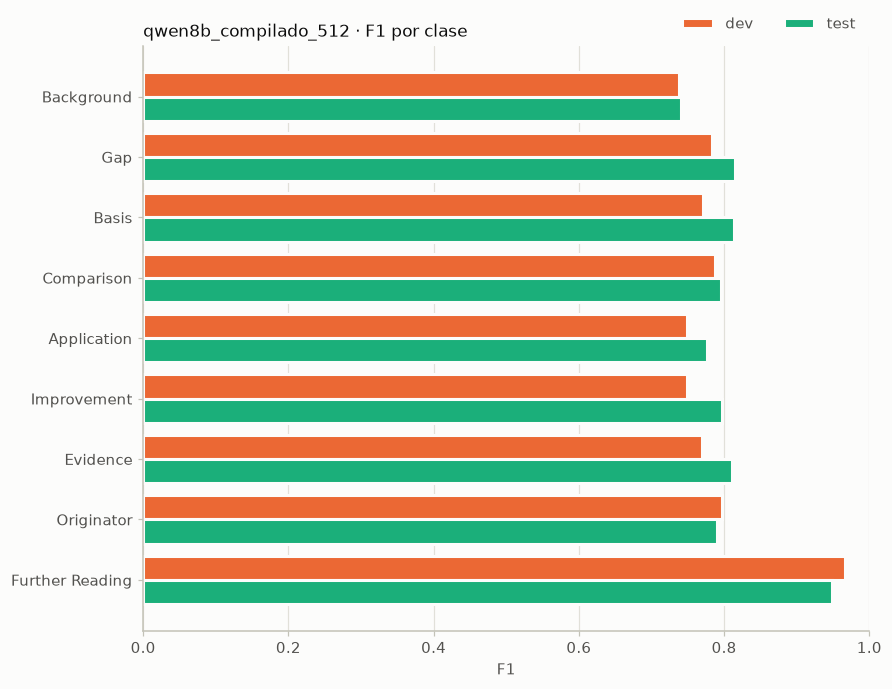

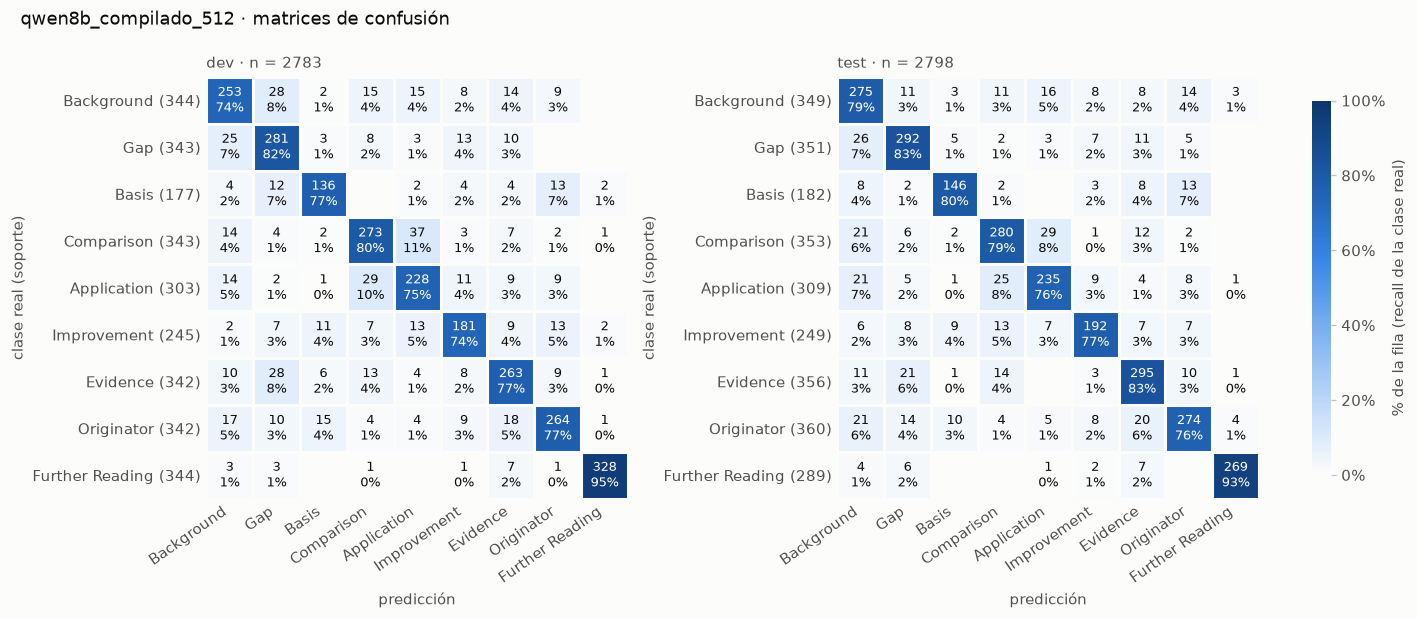

In [6]:
# @title 6 · Análisis de cada corrida
for c in corridas:
    display(Markdown(f"### {c['titulo']}"))
    mostrar(tabla_resumen(c), f"{c['titulo']} · resumen")
    graficar_perdidas(c)
    mostrar(tabla_dev_test(c), f"{c['titulo']} · métricas de dev y test")
    por_clase = tabla_por_clase(c)
    mostrar(por_clase, f"{c['titulo']} · métricas por clase")
    graficar_f1_por_clase(c, por_clase)
    graficar_confusiones(c)

## Todas las corridas

Para elegir modelo, variante o tasa, usa las columnas de dev: test se mira solo para reportar el resultado final, porque elegir con test lo convierte en otro conjunto de validación.

,experimento,familia,modelo,config,variante,lr,mejor época,F1-macro-9 dev,F1-macro-9 test,IC95 test inf.,IC95 test sup.,micro-F1 test,% entrenable,latencia ms,min. entrenamiento
corrida,,,,,,,,,,,,,,,
Qwen3-8B-Base_lora_B_lr1e-4_e4,pipeline_nuevo,llm_lora,Qwen3-8B-Base,B,lora,1e-04,3.99,0.804,0.829,0.815,0.843,0.827,0.57,62.96,120.3
Qwen3-8B-Base_lora_B_lr1e-4_e4_512,pipeline_nuevo,llm_lora,Qwen3-8B-Base,B,lora,1e-04,4.00,0.799,0.824,0.809,0.837,0.820,0.57,41.15,93.7
qwen8b_compilado_1024,pipeline_nuevo,llm_lora,Qwen3-8B-Base,B,lora,1e-04,3.00,0.802,0.809,0.794,0.823,0.808,0.57,39.85,79.7
qwen8b_compilado_512,pipeline_nuevo,llm_lora,Qwen3-8B-Base,B,lora,1e-04,3.00,0.790,0.810,0.796,0.824,0.807,0.57,26.25,64.0


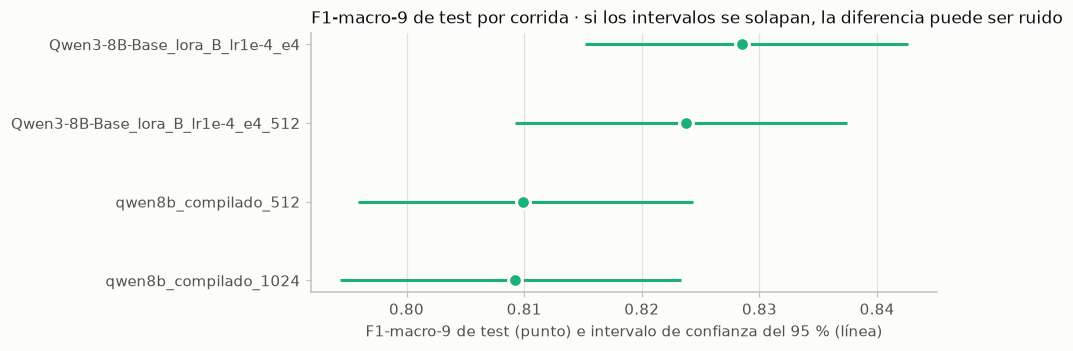

In [7]:
# @title 7 · Comparación entre corridas
def tabla_corridas(corridas: list[dict]) -> pd.DataFrame:
    """Una fila por corrida con su configuración y sus métricas principales de dev y test."""
    filas = {}
    for c in corridas:
        p, m = c["params"], c["metricas"]
        convertir, mejor = a_epoca(c), mejor_paso(c)
        test = c["resumen"].get("test_metrics_a6")
        inferior, superior = ic95_f1_macro(test["confusion_matrix"]) if test else (None, None)
        filas[c["nombre"]] = {
            "experimento": c["experimento"], "familia": p.get("model_family"),
            "modelo": p.get("pretrained_model_name_or_path", "TF-IDF").split("/")[-1],
            "config": p.get("configuration"), "variante": p.get("lora_variant"),
            "lr": float(p["learning_rate"]) if "learning_rate" in p else None,
            "mejor época": float(convertir(mejor)) if convertir and mejor else None,
            "F1-macro-9 dev": m.get("dev_macro_f1_all_9"), "F1-macro-9 test": m.get("test_macro_f1_all_9"),
            "IC95 test inf.": inferior, "IC95 test sup.": superior, "micro-F1 test": m.get("test_micro_f1"),
            "% entrenable": m.get("a7_trainable_ratio_pct"), "latencia ms": m.get("a7_latency_ms"),
            "min. entrenamiento": m.get("a7_train_wall_time_sec", np.nan) / 60,
        }
    tabla = pd.DataFrame(filas).T.rename_axis("corrida")
    texto = ["experimento", "familia", "modelo", "config", "variante"]
    for columna in tabla.columns.drop(texto):
        tabla[columna] = pd.to_numeric(tabla[columna], errors="coerce")
    return tabla


comparacion = tabla_corridas(corridas)
mostrar(comparacion.sort_values(["familia", "modelo", "config", "variante", "lr"], na_position="first"),
        "Todas las corridas", formatos={"lr": "{:.0e}", "mejor época": "{:.2f}", "latencia ms": "{:.2f}",
                                        "min. entrenamiento": "{:.1f}", "% entrenable": "{:.2f}"})
graficar_test_con_ic(comparacion)

## Rankings

El de dev es el que sirve para elegir; el de test, para reportar.

In [8]:
# @title 8 · Rankings por F1-macro-9
if GUARDAR:
    Path("analisis").mkdir(exist_ok=True)
    comparacion.to_csv(Path("analisis") / "comparacion.csv")
for split in ("dev", "test"):
    ranking = (comparacion[f"F1-macro-9 {split}"].dropna().astype(float).sort_values(ascending=False)
               .rename("F1-macro-9").rename_axis("corrida").reset_index())
    ranking.index = range(1, len(ranking) + 1)
    if GUARDAR:
        ranking.to_csv(Path("analisis") / f"ranking_{split}.csv", index_label="puesto")
    mostrar(ranking, f"Ranking en {split} (F1-macro-9)", decimales=4)

,corrida,F1-macro-9
1,Qwen3-8B-Base_lora_B_lr1e-4_e4,0.8036
2,qwen8b_compilado_1024,0.8016
3,Qwen3-8B-Base_lora_B_lr1e-4_e4_512,0.7990
4,qwen8b_compilado_512,0.7901


,corrida,F1-macro-9
1,Qwen3-8B-Base_lora_B_lr1e-4_e4,0.8285
2,Qwen3-8B-Base_lora_B_lr1e-4_e4_512,0.8237
3,qwen8b_compilado_512,0.8099
4,qwen8b_compilado_1024,0.8092


## El mejor modelo de una corrida

Cada corrida registra su mejor modelo en MLflow (columna **Models**): los `.safetensors` con su config y tokenizador (el modelo completo en SciBERT, el adaptador en LoRA) o `tfidf_pipeline.joblib` en TF-IDF. La celda lista sus archivos sin bajarlos; con `BAJAR_MODELO=1` los baja a una carpeta temporal. Desde el repo, `create_predictor(config)` hace lo mismo cuando la corrida no está en local, y `src.modeling.registro_mlflow.descargar_modelo(config, destino)` lo baja a la carpeta que se le indique.

In [9]:
# @title 9 · Archivos del mejor modelo (por defecto, de la mejor corrida en dev)
CORRIDA_MODELO = os.environ.get("CORRIDA_MODELO") or comparacion["F1-macro-9 dev"].astype(float).idxmax()
c = next(c for c in corridas if c["nombre"] == CORRIDA_MODELO)
if c["modelo"] is None:
    print(f"{CORRIDA_MODELO} no tiene modelo registrado")
else:
    ubicacion = cliente.get_logged_model(c["modelo"]).artifact_location
    archivos = [(a.path.removeprefix("artifacts/"), a.file_size)
                for a in list_artifacts(artifact_uri=ubicacion, tracking_uri=MLFLOW_URI)]
    print(f"{CORRIDA_MODELO} · modelo {c['modelo']} · {ubicacion}")
    for ruta, tamano in archivos:
        print(f"  {ruta:<34}{'(carpeta)' if tamano is None else f'{tamano / 1024:,.0f} KB'}")
    if os.environ.get("BAJAR_MODELO") == "1":
        carpeta = download_artifacts(artifact_uri=ubicacion, dst_path=tempfile.mkdtemp(), tracking_uri=MLFLOW_URI)
        print(f"descargado en {carpeta}: {sorted(p.name for p in Path(carpeta).iterdir())}")

Qwen3-8B-Base_lora_B_lr1e-4_e4 · modelo m-15f242232e3a4aacb021f6f5c5568df0 · mlflow-artifacts:/2/models/m-15f242232e3a4aacb021f6f5c5568df0/artifacts
  README.md                         5 KB
  adapter_config.json               1 KB
  adapter_model.safetensors         170,706 KB
  chat_template.jinja               4 KB
  tokenizer.json                    11,155 KB
  tokenizer_config.json             1 KB
  training_args.bin                 5 KB
